1. Importação das bibliotecas

In [2]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

2. Carregamento dos dados

In [3]:
df = pd.read_csv('microdados_enem_2016.csv', sep=';', encoding='latin-1')


3. Filtro geográfico (Nordeste)

In [4]:
estados_nordeste = ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE']

df = df[df['SG_UF_ESC'].isin(estados_nordeste)]

4. Limpeza dos dados (presença nas provas)

In [5]:
df = df[df['IN_TREINEIRO'] == 0]
df = df[df['TP_PRESENCA_CN'] == 1]
df = df[df['TP_PRESENCA_CH'] == 1]
df = df[df['TP_PRESENCA_LC'] == 1]
df = df[df['TP_PRESENCA_MT'] == 1]

5. Criação da variável dependente (nota média)

In [6]:
df['NOTA_MEDIA'] = df[['NU_NOTA_MT', 'NU_NOTA_LC', 'NU_NOTA_CH', 'NU_NOTA_CN']].mean(axis=1)

6. Variáveis de tecnologia

In [7]:
def tem_internet(x):
    return 1 if x in ['B', 'C', 'D', 'E'] else 0

df['INTERNET'] = df['Q025'].apply(tem_internet)

In [8]:
def tem_computador(x):
    return 1 if x in ['B', 'C', 'D', 'E'] else 0

df['COMPUTADOR'] = df['Q024'].apply(tem_computador)

In [9]:
def tem_celular(x):
    return 1 if x in ['B', 'C', 'D', 'E'] else 0

df['CELULAR'] = df['Q022'].apply(tem_celular)

7. Variável de renda 

In [10]:
def renda(x):
    if x in ['A', 'B']:
        return 'baixa_renda'
    
    elif x == 'C':
        return 'baixa_classe_media'
    
    elif x in ['D', 'E']:
        return 'classe_media'
    
    elif x in ['F', 'G']:
        return 'alta_classe_media'
    
    elif x in ['H', 'I', 'J']:
        return 'alta_renda'
    
    else:
        return 'nao_respondeu'

8. Tipo de escola

In [11]:
df['RENDA'] = df['Q006'].apply(renda)
df['ESCOLA'] = df['TP_ESCOLA'].map({
    2: 'publica',
    3: 'privada'
})

9. Base final do modelo

In [12]:
df_modelo = df[['NOTA_MEDIA', 'INTERNET', 'COMPUTADOR', 'CELULAR', 'RENDA', 'ESCOLA']].dropna()

Extra: tamanho da amostra

In [13]:
print("Quantidade de dados usados:", len(df_modelo))

Quantidade de dados usados: 426272


10. Regressão linear (OLS)

In [14]:
modelo = smf.ols(
    'NOTA_MEDIA ~ C(RENDA, Treatment(reference="baixa_classe_media")) + C(ESCOLA, Treatment(reference="publica")) + INTERNET + COMPUTADOR + CELULAR',
    data=df_modelo
).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:             NOTA_MEDIA   R-squared:                       0.322
Model:                            OLS   Adj. R-squared:                  0.322
Method:                 Least Squares   F-statistic:                 2.250e+04
Date:                Thu, 30 Apr 2026   Prob (F-statistic):               0.00
Time:                        01:53:48   Log-Likelihood:            -2.2986e+06
No. Observations:              426272   AIC:                         4.597e+06
Df Residuals:                  426262   BIC:                         4.597e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

11. Resultado

In [15]:
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:             NOTA_MEDIA   R-squared:                       0.322
Model:                            OLS   Adj. R-squared:                  0.322
Method:                 Least Squares   F-statistic:                 2.250e+04
Date:                Thu, 30 Apr 2026   Prob (F-statistic):               0.00
Time:                        01:53:48   Log-Likelihood:            -2.2986e+06
No. Observations:              426272   AIC:                         4.597e+06
Df Residuals:                  426262   BIC:                         4.597e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

TABELAS

In [16]:
df_modelo.groupby('INTERNET')['NOTA_MEDIA'].mean()

INTERNET
0    469.074390
1    511.422083
Name: NOTA_MEDIA, dtype: float64

In [17]:
df_modelo.groupby('COMPUTADOR')['NOTA_MEDIA'].mean()

COMPUTADOR
0    469.686045
1    516.473740
Name: NOTA_MEDIA, dtype: float64

In [18]:
df_modelo.groupby('CELULAR')['NOTA_MEDIA'].mean()

CELULAR
0    464.741059
1    492.477711
Name: NOTA_MEDIA, dtype: float64

GERAR GRAFICOS

1. Distribuição da nota média 2016

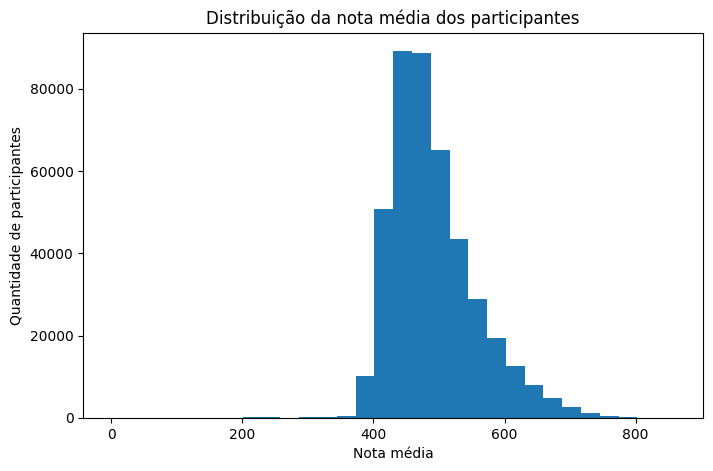

In [19]:
plt.figure(figsize=(8,5))
plt.hist(df_modelo['NOTA_MEDIA'], bins=30)
plt.title('Distribuição da nota média dos participantes')
plt.xlabel('Nota média')
plt.ylabel('Quantidade de participantes')
plt.show()

A maior parte dos participantes se concentra em determinada faixa de desempenho.

2. Nota média por acesso à internet

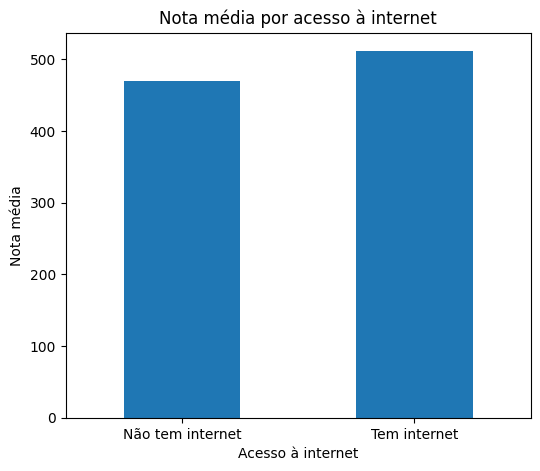

In [20]:
media_internet = df_modelo.groupby('INTERNET')['NOTA_MEDIA'].mean()

plt.figure(figsize=(6,5))
media_internet.plot(kind='bar')
plt.title('Nota média por acesso à internet')
plt.xlabel('Acesso à internet')
plt.ylabel('Nota média')
plt.xticks([0,1], ['Não tem internet', 'Tem internet'], rotation=0)
plt.show()

Participantes com acesso à internet apresentam média superior/inferior aos que não possuem.

3. Nota média por computador

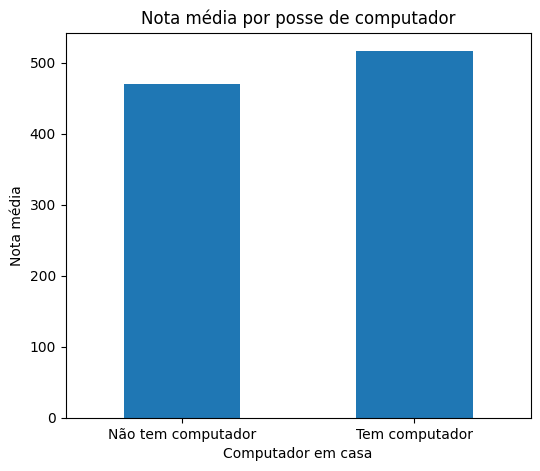

In [21]:
media_computador = df_modelo.groupby('COMPUTADOR')['NOTA_MEDIA'].mean()

plt.figure(figsize=(6,5))
media_computador.plot(kind='bar')
plt.title('Nota média por posse de computador')
plt.xlabel('Computador em casa')
plt.ylabel('Nota média')
plt.xticks([0,1], ['Não tem computador', 'Tem computador'], rotation=0)
plt.show()

Esse é muito importante porque, no seu modelo anterior, computador teve impacto forte.

4. Nota média por celular

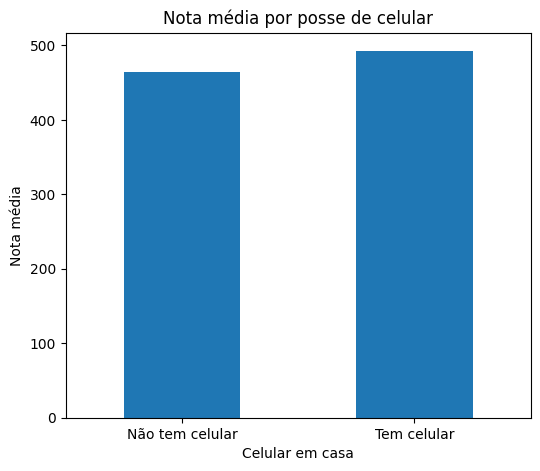

In [22]:
media_celular = df_modelo.groupby('CELULAR')['NOTA_MEDIA'].mean()

plt.figure(figsize=(6,5))
media_celular.plot(kind='bar')
plt.title('Nota média por posse de celular')
plt.xlabel('Celular em casa')
plt.ylabel('Nota média')
plt.xticks([0,1], ['Não tem celular', 'Tem celular'], rotation=0)
plt.show()

5. Nota média por renda

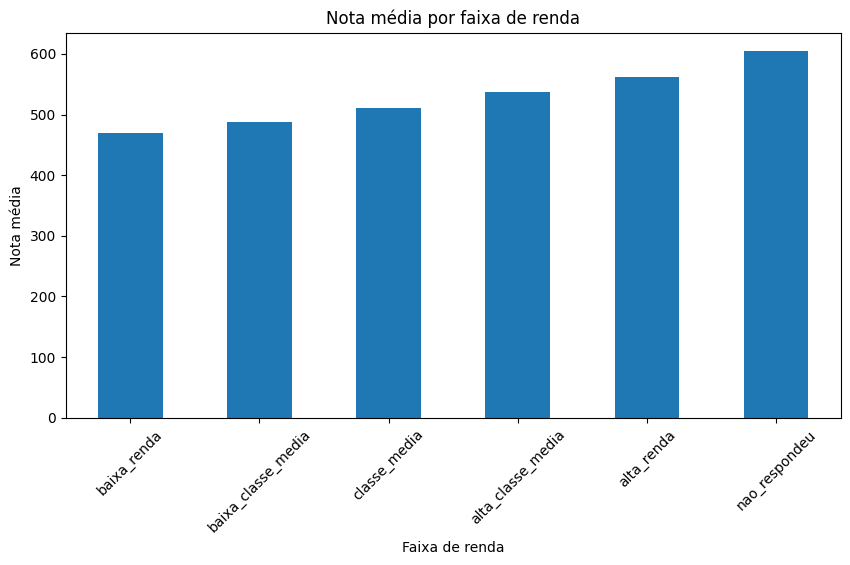

In [23]:
ordem_renda = [
    'baixa_renda',
    'baixa_classe_media',
    'classe_media',
    'alta_classe_media',
    'alta_renda',
    'nao_respondeu'
]

media_renda = df_modelo.groupby('RENDA')['NOTA_MEDIA'].mean().reindex(ordem_renda)

plt.figure(figsize=(10,5))
media_renda.plot(kind='bar')
plt.title('Nota média por faixa de renda')
plt.xlabel('Faixa de renda')
plt.ylabel('Nota média')
plt.xticks(rotation=45)
plt.show()

Esse gráfico ajuda muito a mostrar desigualdade socioeconômica.

6. Nota média por tipo de escola

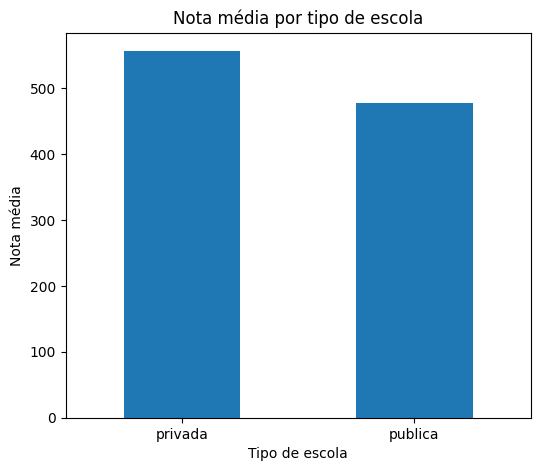

In [24]:
media_escola = df_modelo.groupby('ESCOLA')['NOTA_MEDIA'].mean()

plt.figure(figsize=(6,5))
media_escola.plot(kind='bar')
plt.title('Nota média por tipo de escola')
plt.xlabel('Tipo de escola')
plt.ylabel('Nota média')
plt.xticks(rotation=0)
plt.show()

7. Gráfico dos coeficientes da regressão

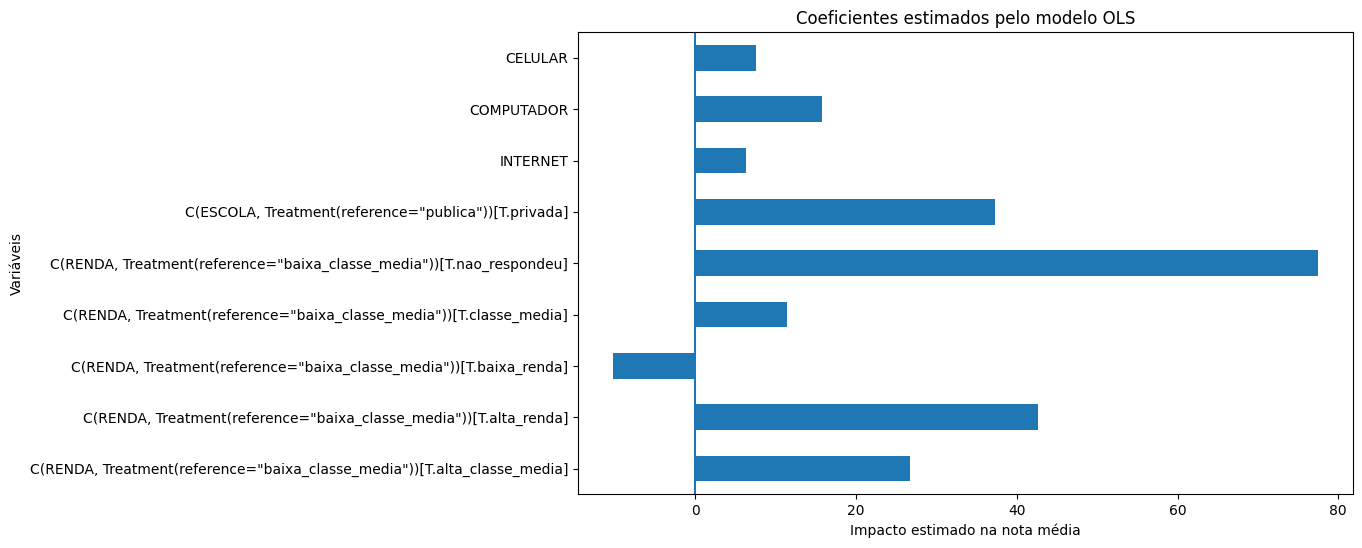

In [25]:
coeficientes = modelo.params.drop('Intercept')

plt.figure(figsize=(10,6))
coeficientes.plot(kind='barh')
plt.title('Coeficientes estimados pelo modelo OLS')
plt.xlabel('Impacto estimado na nota média')
plt.ylabel('Variáveis')
plt.axvline(0)
plt.show()

Valores positivos indicam aumento estimado na nota média; valores negativos indicam redução estimada.

In [42]:
tabela_renda = df['Q006'].value_counts().sort_index().reset_index()

tabela_renda.columns = ['Renda', 'Quantidade']

tabela_renda['Porcentagem'] = (
    tabela_renda['Quantidade'] / tabela_renda['Quantidade'].sum() * 100
).round(2)

mapa_renda = {
    'A': 'Nenhuma renda',
    'B': 'Até 1 salário mínimo',
    'C': 'De 1 a 2 salários mínimos',
    'D': 'De 2 a 3 salários mínimos',
    'E': 'De 3 a 4 salários mínimos',
    'F': 'De 4 a 5 salários mínimos',
    'G': 'De 5 a 6 salários mínimos',
    'H': 'De 6 a 7 salários mínimos',
    'I': 'De 7 a 8 salários mínimos',
    'J': 'De 8 a 9 salários mínimos',
    'K': 'De 9 a 10 salários mínimos',
    'L': 'De 10 a 12 salários mínimos',
    'M': 'De 12 a 15 salários mínimos',
    'N': 'De 15 a 20 salários mínimos',
    'O': 'De 20 a 30 salários mínimos',
    'P': 'Acima de 30 salários mínimos',
    'Q': 'Não sei'
}

tabela_renda['Descrição'] = tabela_renda['Renda'].map(mapa_renda)

tabela_renda = tabela_renda[['Renda', 'Descrição', 'Quantidade', 'Porcentagem']]

tabela_renda

,Renda,Descrição,Quantidade,Porcentagem
0,A,Nenhuma renda,23217,5.45
1,B,Até 1 salário mínimo,196825,46.17
2,C,De 1 a 2 salários mínimos,95830,22.48
3,D,De 2 a 3 salários mínimos,32914,7.72
4,E,De 3 a 4 salários mínimos,18387,4.31
5,F,De 4 a 5 salários mínimos,11896,2.79
6,G,De 5 a 6 salários mínimos,12231,2.87
7,H,De 6 a 7 salários mínimos,8789,2.06
8,I,De 7 a 8 salários mínimos,6421,1.51
9,J,De 8 a 9 salários mínimos,4301,1.01


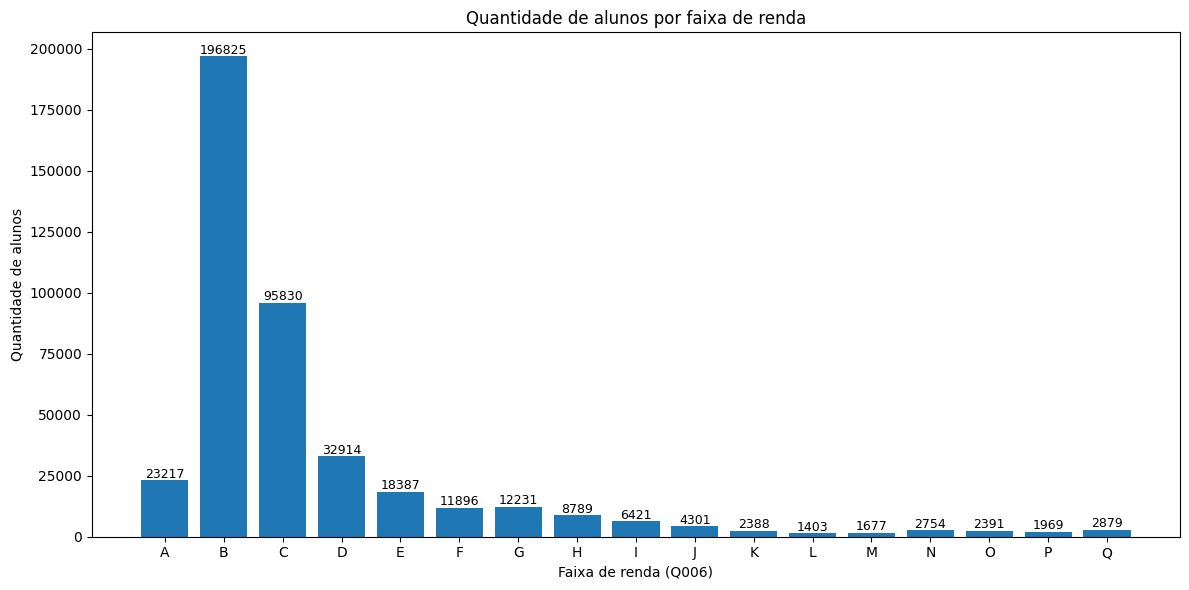

In [43]:


# Contagem de cada categoria de renda
contagem_renda = df['Q006'].value_counts().sort_index()

# Criando o gráfico
plt.figure(figsize=(12, 6))
plt.bar(contagem_renda.index, contagem_renda.values)

# Títulos e rótulos
plt.title('Quantidade de alunos por faixa de renda')
plt.xlabel('Faixa de renda (Q006)')
plt.ylabel('Quantidade de alunos')

# Mostrar valores em cima das barras
for i, valor in enumerate(contagem_renda.values):
    plt.text(i, valor + 1000, str(valor), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

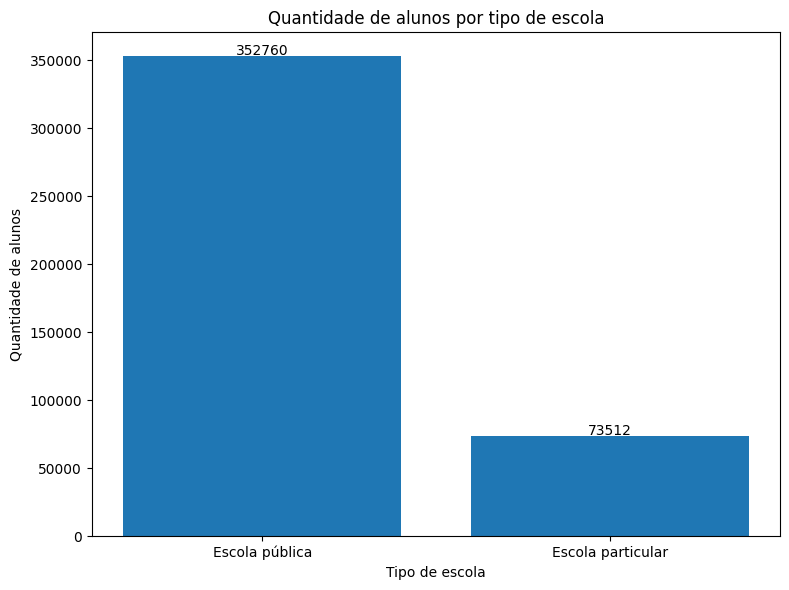

In [44]:
# Contagem por tipo de escola
contagem_escola = df['TP_ESCOLA'].value_counts().sort_index()

# Mapeando os códigos
mapa_escola = {
    1: 'Não respondeu',
    2: 'Escola pública',
    3: 'Escola particular'
}

labels = [mapa_escola.get(i, i) for i in contagem_escola.index]

# Criando o gráfico
plt.figure(figsize=(8, 6))
plt.bar(labels, contagem_escola.values)

plt.title('Quantidade de alunos por tipo de escola')
plt.xlabel('Tipo de escola')
plt.ylabel('Quantidade de alunos')

# Mostrar os valores em cima das barras
for i, valor in enumerate(contagem_escola.values):
    plt.text(i, valor + 1000, str(valor), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

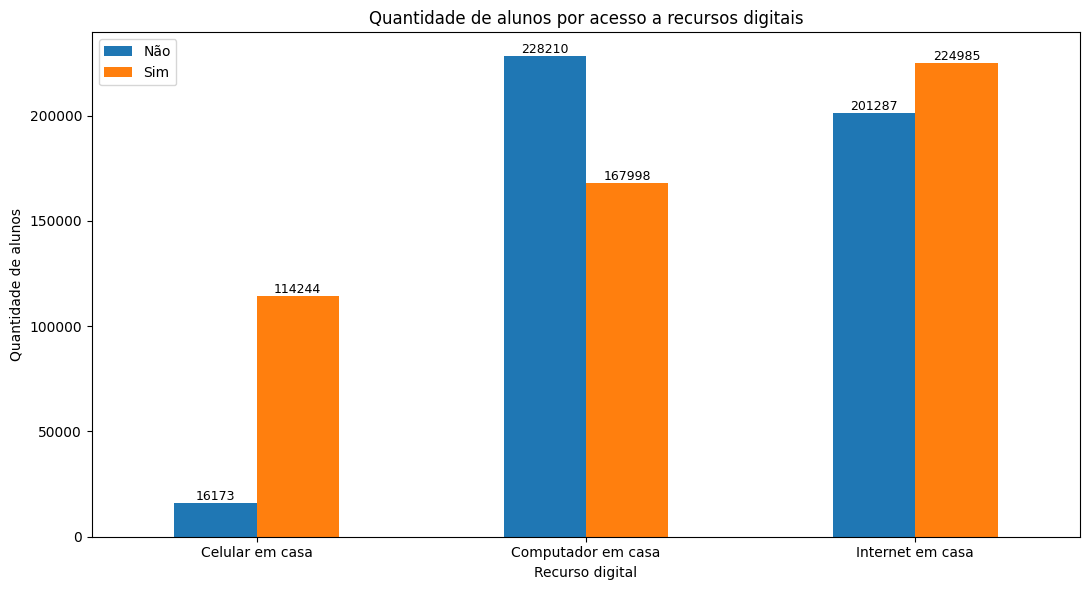

In [45]:
mapa_sim_nao = {
    'A': 'Não',
    'B': 'Sim'
}

recursos_digitais = {
    'Celular em casa': df['Q022'].map(mapa_sim_nao).value_counts(),
    'Computador em casa': df['Q024'].map(mapa_sim_nao).value_counts(),
    'Internet em casa': df['Q025'].map(mapa_sim_nao).value_counts()
}

tabela_recursos = pd.DataFrame(recursos_digitais).T
tabela_recursos = tabela_recursos[['Não', 'Sim']]

ax = tabela_recursos.plot(kind='bar', figsize=(11, 6))

plt.title('Quantidade de alunos por acesso a recursos digitais')
plt.xlabel('Recurso digital')
plt.ylabel('Quantidade de alunos')
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=9)

plt.tight_layout()
plt.show()

In [46]:
# Participantes que NÃO têm nenhum dos recursos digitais
sem_recursos = df[
    (df['Q022'] == 'A') &
    (df['Q024'] == 'A') &
    (df['Q025'] == 'A')
]

quantidade_sem_recursos = len(sem_recursos)

quantidade_sem_recursos

12882

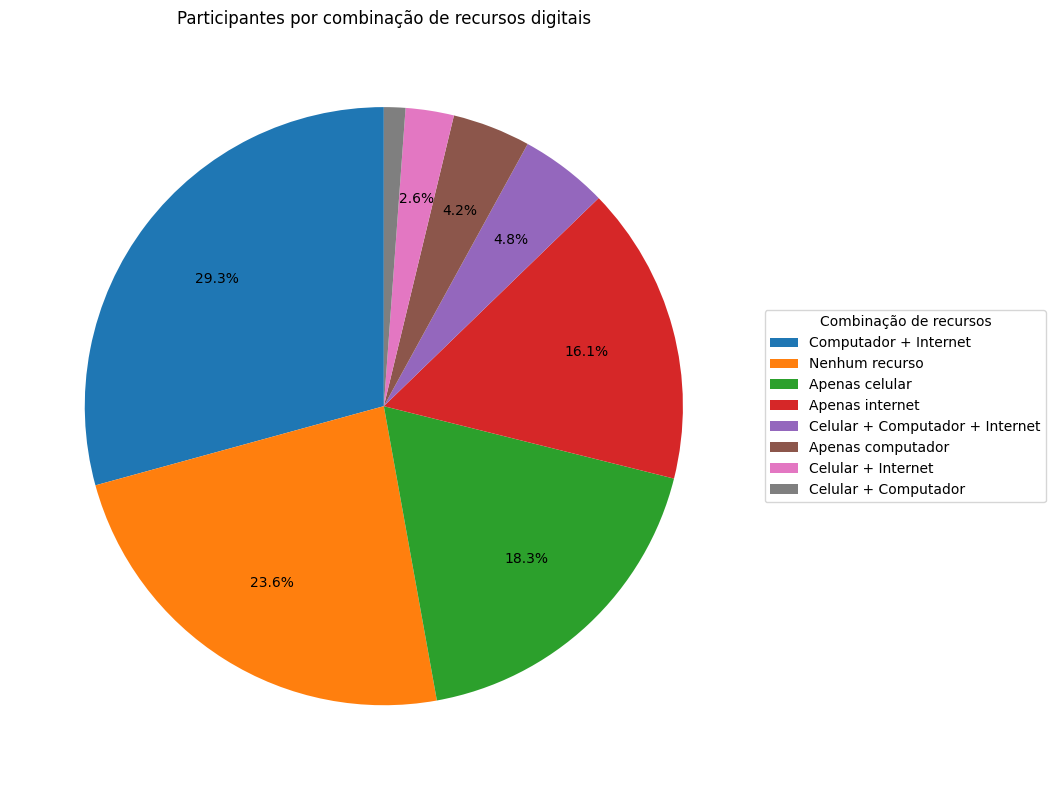

In [48]:
def classificar_recursos(row):
    celular = row['Q022'] == 'B'
    computador = row['Q024'] == 'B'
    internet = row['Q025'] == 'B'

    if celular and computador and internet:
        return 'Celular + Computador + Internet'
    elif celular and computador:
        return 'Celular + Computador'
    elif celular and internet:
        return 'Celular + Internet'
    elif computador and internet:
        return 'Computador + Internet'
    elif celular:
        return 'Apenas celular'
    elif computador:
        return 'Apenas computador'
    elif internet:
        return 'Apenas internet'
    else:
        return 'Nenhum recurso'

# Criando a coluna
df['GRUPO_RECURSOS_DIGITAIS'] = df.apply(classificar_recursos, axis=1)

# Contagem
contagem_recursos = df['GRUPO_RECURSOS_DIGITAIS'].value_counts()

# Gráfico de pizza melhorado
plt.figure(figsize=(11, 8))

wedges, texts, autotexts = plt.pie(
    contagem_recursos.values,
    labels=None,  # remove os nomes das fatias
    autopct=lambda p: f'{p:.1f}%' if p > 2 else '',  # mostra % só se for maior que 2%
    startangle=90,
    pctdistance=0.7
)

# Legenda ao lado
plt.legend(
    wedges,
    contagem_recursos.index,
    title='Combinação de recursos',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

plt.title('Participantes por combinação de recursos digitais')
plt.tight_layout()
plt.show()